Проведение EDA в рамках годового проекта (checkpoint 2) на тему up-lift моделирование. 
Dataset - X5

In [309]:
from sklift.datasets import fetch_x5
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

x5_data = fetch_x5()


In [ ]:
df_train = x5_data.data['train'].copy()
df_train['target'] = x5_data.target
df_train['treatment_flg'] = x5_data.treatment

df_clients = pd.merge(
    df_train, 
    x5_data.data['clients'], 
    on='client_id', 
    how='left'
)

df_purchases = x5_data.data['purchases']

print(f"Таблица df_clients имеет форму {df_clients.shape}")
print(f"Таблица df_purchases имеет форму {df_purchases.shape}")
display(df_clients.head())
display(df_purchases.head())

Таблица df_clients имеет форму (200039, 7)
Таблица df_purchases имеет форму (45786568, 13)


,client_id,target,treatment_flg,first_issue_date,first_redeem_date,age,gender
0,000012768d,1,0,2017-08-05 15:40:48,2018-01-04 19:30:07,45,U
1,000036f903,1,1,2017-04-10 13:54:23,2017-04-23 12:37:56,72,F
2,00010925a5,1,1,2018-07-24 16:21:29,2018-09-14 16:12:49,83,U
3,0001f552b0,1,1,2017-06-30 19:20:38,2018-08-28 12:59:45,33,F
4,00020e7b18,1,1,2017-11-27 11:41:45,2018-01-10 17:50:05,73,U


,client_id,transaction_id,transaction_datetime,regular_points_received,express_points_received,regular_points_spent,express_points_spent,purchase_sum,store_id,product_id,product_quantity,trn_sum_from_iss,trn_sum_from_red
0,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,9a80204f78,2.0,80.0,NaN
1,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,da89ebd374,1.0,65.0,NaN
2,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,0a95e1151d,1.0,24.0,NaN
3,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,4055b15e4a,2.0,50.0,NaN
4,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,a685f1916b,1.0,22.0,NaN


In [311]:
display(df_clients.describe(include='all').round(2))
display(df_purchases.describe(include='all').round(2))


,client_id,target,treatment_flg,first_issue_date,first_redeem_date,age,gender
count,200039,200039.00,200039.0,200039,182493,200039.00,200039
unique,200039,NaN,NaN,199185,181971,NaN,3
top,000012768d,NaN,NaN,2017-06-01 20:48:29,2018-12-29 19:07:00,NaN,U
freq,1,NaN,NaN,3,3,NaN,92832
mean,NaN,0.62,0.5,NaN,NaN,46.42,NaN
std,NaN,0.49,0.5,NaN,NaN,49.53,NaN
min,NaN,0.00,0.0,NaN,NaN,-7491.00,NaN
25%,NaN,0.00,0.0,NaN,NaN,34.00,NaN
50%,NaN,1.00,0.0,NaN,NaN,45.00,NaN
75%,NaN,1.00,1.0,NaN,NaN,59.00,NaN


,client_id,transaction_id,transaction_datetime,regular_points_received,express_points_received,regular_points_spent,express_points_spent,purchase_sum,store_id,product_id,product_quantity,trn_sum_from_iss,trn_sum_from_red
count,45786568,45786568,45786568,45786568.00,45786568.00,45786568.00,45786568.00,45786568.00,45786568,45786568,45786568.00,45786568.00,3043356.00
unique,400162,8045201,4260251,NaN,NaN,NaN,NaN,NaN,13882,42530,NaN,NaN,NaN
top,7a73214c0b,f9a45c98e1,2019-02-07 15:12:53,NaN,NaN,NaN,NaN,NaN,cfbbd53ab7,4009f09b04,NaN,NaN,NaN
freq,2513,116,150,NaN,NaN,NaN,NaN,NaN,18984,1824586,NaN,NaN,NaN
mean,NaN,NaN,NaN,8.05,0.06,-5.31,-0.32,777.52,NaN,NaN,1.25,73.49,76.77
std,NaN,NaN,NaN,12.69,2.43,36.04,3.29,796.54,NaN,NaN,3.14,87.54,84.27
min,NaN,NaN,NaN,0.00,0.00,-5066.00,-300.00,0.00,NaN,NaN,0.00,0.00,0.00
25%,NaN,NaN,NaN,1.40,0.00,0.00,0.00,286.00,NaN,NaN,1.00,30.00,31.00
50%,NaN,NaN,NaN,3.80,0.00,0.00,0.00,539.00,NaN,NaN,1.00,51.00,55.00
75%,NaN,NaN,NaN,10.30,0.00,0.00,0.00,976.00,NaN,NaN,1.00,90.00,95.00


Все клиенты имеют уникальный id - повторов нет, это хорошо.
2166 человек еще не воспользовались скидкой. У большей части клиентов не задан пол. Стоит отметить, что при списании баллов их количество выражено отрицательным числом. 
Минимальный возраст клиентов минус 7491 год, максимальный 1901 год - значит в данных есть ошибки, в дальнейшем обратим на это внимание.

 У 0.328% клиентов задан нереалистичный возраст (меньше 14 или больше 120 лет).


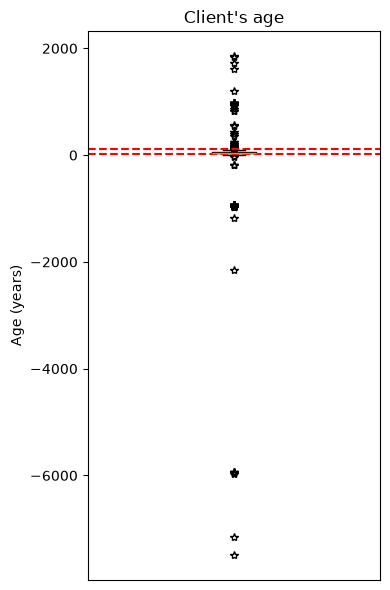

In [324]:
print(f" У {(100 - (((df_clients.age > 14) & (df_clients.age < 120)).sum() / df_clients.shape[0] * 100)).round(3)}% клиентов задан нереалистичный возраст (меньше 14 или больше 120 лет).")

fig, ax = plt.subplots(figsize=(4, 6))
ax.boxplot(df_clients['age'].dropna(), sym='*')
ax.set_title("Client's age"),
ax.set_ylabel('Age (years)')
ax.axhline(y=14, color='red', linestyle='--', linewidth=1.5)
ax.axhline(y=120, color='red', linestyle='--', linewidth=1.5)
ax.set_xticks([])
plt.tight_layout()
plt.show()

Исправим это, подставив медианное значение.

In [ ]:
valid_mask = (df_clients['age'] >= 14) & (df_clients['age'] <= 120)

median_age = df_clients.loc[valid_mask, 'age'].median()
df_clients.loc[~valid_mask, 'age'] = median_age

print(f"Медиана = {median_age}")
print(f"Исправлено значений: {(~valid_mask).sum()}")


Медиана = 45.0
Выявлено и исправлено: 474


In [327]:
#считаем количество пропусков в таблицах
display(df_clients.isna().sum())
display(df_purchases.isna().sum())

client_id                0
target                   0
treatment_flg            0
first_issue_date         0
first_redeem_date    17546
age                      0
gender                   0
dtype: int64

client_id                         0
transaction_id                    0
transaction_datetime              0
regular_points_received           0
express_points_received           0
regular_points_spent              0
express_points_spent              0
purchase_sum                      0
store_id                          0
product_id                        0
product_quantity                  0
trn_sum_from_iss                  0
trn_sum_from_red           42743212
dtype: int64

Видим пропуски в признаке first_redeem_date, это объясняется тем, что клиет еще не воспользовался скидкой. trn_sum_from_red - аналогично. 
Фактически, пропуски отсутсвуют, что не может не радовать. 

Построим графики временных и численных признаков для их оценки. 

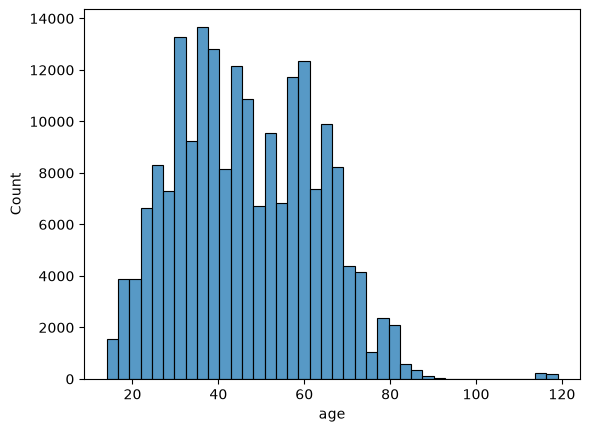

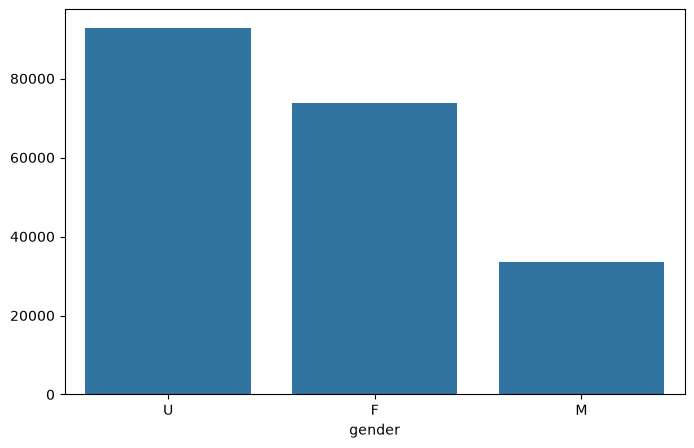

In [330]:
sns.histplot(df_clients['age'], bins=40)

plt.figure(figsize=(8, 5))

gender_counts = df_clients['gender'].value_counts()
ax = sns.barplot(
    x=gender_counts.index, 
    y=gender_counts.values, 
    legend=False
)


Видим адекватное распределение возрастов клиентов. Кроме того, большая часть их них не указала свой пол, из тех кто указал, женщин в 2 раза больше, чем мужчин. 

Проверим есть ли клиенты, у которых дата списания баллов меньше даты получения карты. 

In [331]:
issue_dt = pd.to_datetime(df_clients['first_issue_date'])
redeem_dt = pd.to_datetime(df_clients['first_redeem_date'])

count = (redeem_dt < issue_dt).sum()
print(f"Списание раньше выдачи карты: {count} чел.")

Списание раньше выдачи карты: 245 чел.


Это похоже на ошибки в данных. В дальнейшем не будем учитывать данных клиентов при обучении. 

Чтобы построить матрицу корреляции агрегируем данные о покупках клиентов и дополним таблицу. 

In [332]:
clients = df_clients.copy()

clients['first_issue_date'] = pd.to_datetime(clients['first_issue_date'])
clients['first_redeem_date'] = pd.to_datetime(clients['first_redeem_date'])

# Кодируем пол
clients['gender_code'] = clients['gender'].map({'U': -1, 'F': 0, 'M': 1}).fillna(-1)

# Корректируем дату старта (берем минимальную из двух дат, если списание было раньше выдачи)
clients['true_start_date'] = clients[['first_issue_date', 'first_redeem_date']].min(axis=1)
clients['has_redeemed'] = clients['first_redeem_date'].notna().astype(int)

df_purchases['transaction_datetime'] = pd.to_datetime(df_purchases['transaction_datetime'])
cutoff_date = df_purchases['transaction_datetime'].max()  # Точка отсечения (конец истории)

tx_agg = df_purchases.groupby(['client_id', 'transaction_id'], as_index=False).agg(
    tx_datetime=('transaction_datetime', 'first'),
    purchase_sum=('purchase_sum', 'first'),
    reg_pts_rec=('regular_points_received', 'first'),
    exp_pts_rec=('express_points_received', 'first'),
    reg_pts_spent=('regular_points_spent', 'first'),
    exp_pts_spent=('express_points_spent', 'first'),
    items_in_tx=('product_quantity', 'sum'),
    unique_products=('product_id', 'nunique')
)

purch_agg = tx_agg.groupby('client_id', as_index=False).agg(
    total_spend=('purchase_sum', 'sum'),
    visits=('transaction_id', 'count'),
    total_items=('items_in_tx', 'sum'),
    avg_unique_products=('unique_products', 'mean'),
    reg_points_received=('reg_pts_rec', 'sum'),
    reg_points_spent=('reg_pts_spent', 'sum'),
    exp_points_spent=('exp_pts_spent', 'sum'),
    last_purchase_date=('tx_datetime', 'max'),
    first_purchase_date=('tx_datetime', 'min')
)

purch_agg['average_check'] = purch_agg['total_spend'] / purch_agg['visits']
purch_agg['recency_days'] = (cutoff_date - purch_agg['last_purchase_date']).dt.total_seconds() / (3600 * 24)
purch_agg['active_span_days'] = (purch_agg['last_purchase_date'] - purch_agg['first_purchase_date']).dt.days
purch_agg['points_spent_ratio'] = purch_agg['reg_points_spent'].abs() / (purch_agg['total_spend'] + 1)

df_client_info = clients.merge(purch_agg, on='client_id', how='left')

df_client_info['card_tenure_days'] = (cutoff_date - df_client_info['true_start_date']).dt.days

cols_to_drop = ['first_issue_date', 'first_redeem_date', 'true_start_date', 
                'last_purchase_date', 'first_purchase_date', 'gender']
df_numeric = df_client_info.drop(columns=cols_to_drop)


В задачах по uplift-моделированию оценка матрицы корреляции имеет ряд особенностей. Одним из наиболее важных условий однородности контрольных групп является низкая корреляция treatment_flg с другими фичами. В нашем датасете это условие выполняется.  
Кроме того, можно отметить сильную корреляцию между признаками: (average_check и avg_item_price), (total_spend и total_items), (visits и total_items) и др. 

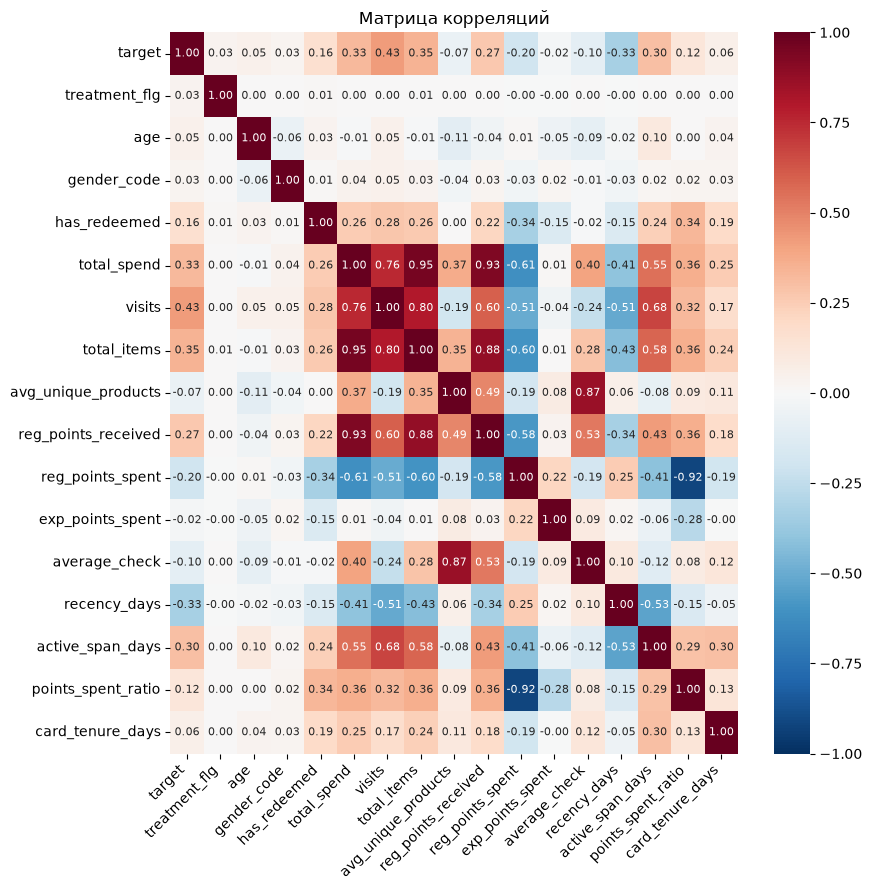

In [345]:
train_numeric = df_numeric.dropna(subset=['target', 'treatment_flg']).drop(columns=['client_id'])

plt.figure(figsize=(9, 9))
corr_matrix = train_numeric.corr(method='spearman')

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='RdBu_r', 
    center=0,
    vmin=-1, vmax=1,
    annot_kws={"size": 8}
)
plt.title('Матрица корреляций')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Видим что на таргет сильное влияние оказывают количество визитов (0.43), число купленных товаров (0.35), общие траты (0.33),  давность последнего визита (-0.33) и длительность активности (0.3) - что, в целом, соответствует здравому смыслу. Кроме того, ряд признаков имеют корреляцию больше 0.9, в будущем обратим на них внимание, вероятно они избыточны.

Разделим выборки на целевую и контрольную. Оценим насколько изменяется корреляция после воздействия. 

,Treatment (1),Control (0),(Treat - Ctrl)
exp_points_spent,-0.0341,-0.0032,-0.0309
age,0.0683,0.0391,0.0292
total_spend,0.3119,0.3396,-0.0277
total_items,0.3332,0.3600,-0.0268
reg_points_received,0.2536,0.2776,-0.0240


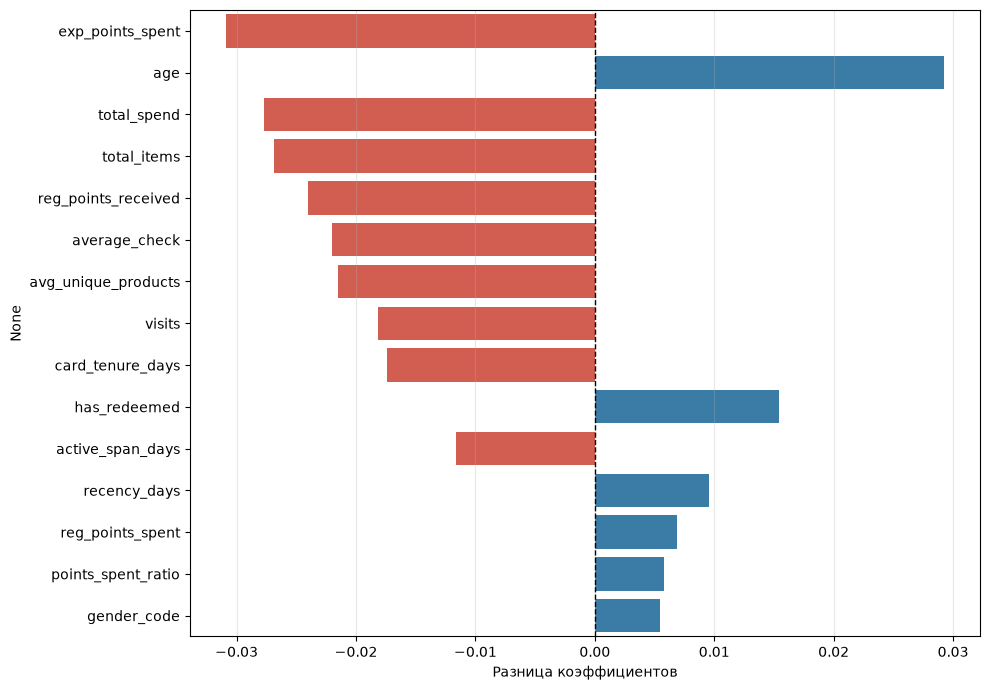

In [355]:
df_treat = train_numeric[train_numeric['treatment_flg'] == 1].drop(columns=['treatment_flg'])
df_ctrl = train_numeric[train_numeric['treatment_flg'] == 0].drop(columns=['treatment_flg'])

corr_treat = df_treat.corr(method='spearman')['target'].drop('target')
corr_ctrl = df_ctrl.corr(method='spearman')['target'].drop('target')

uplift_comparison = pd.DataFrame({
    'Treatment (1)': corr_treat,
    'Control (0)': corr_ctrl,
    '(Treat - Ctrl)': corr_treat - corr_ctrl,
    'Модуль разницы': (corr_treat - corr_ctrl).abs()
})
uplift_comparison = uplift_comparison.sort_values(by='Модуль разницы', ascending=False)

display(uplift_comparison.drop(columns=['Модуль разницы'])[:5].round(4))

plt.figure(figsize=(10, 7))
colors = ['#2980b9' if x > 0 else '#e74c3c' for x in uplift_comparison['(Treat - Ctrl)']]

sns.barplot(
    x=uplift_comparison['(Treat - Ctrl)'],
    y=uplift_comparison.index,
    hue=uplift_comparison.index,
    palette=colors,
    legend=False
)

plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.xlabel('Разница коэффициентов')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


1. Клиенты, активно использующие экспресс-баллы, дают наилучший эффект от тритмента. 
2. Более возрастные клиенты чаще совершают покупку после воздействия (отправка СМС).
3. Тритмент стимулирует к покупке клиентов, которые продолжительное время не совершали покупки.

Таким образом, мы провели EDA датасета Х5 для uplift-моделирования.
В ходе EDA были загружены исходные данные, проведен первичный анализ, выявлены и исправлены аномалии. Сформированы новые агрегированные признаки. По полученным данным построена матрица корреляций. Проведена оценка качества разбиения на целевую и контрольную группы. Оценено изменение коррелиций после тритмента.
